# Лабораторная работа №1

## Задания

![Задания](./tasks.png "Задания")

## Библиотеки

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

## Реализация

### Загрузка данных

In [2]:
df = pd.read_csv("series.csv", parse_dates=["timestamp"])
df.head()

,timestamp,value
0,2026-11-18 00:00:00,101.995074
1,2026-11-18 01:00:00,94.934438
2,2026-11-18 02:00:00,96.359036
3,2026-11-18 03:00:00,69.061720
4,2026-11-18 04:00:00,81.446906


### Сортировка и проверка дубликатов

In [3]:
df = df.sort_values("timestamp").drop_duplicates("timestamp").set_index("timestamp")
df.head()

,value
timestamp,
2026-11-18 00:00:00,101.995074
2026-11-18 01:00:00,94.934438
2026-11-18 02:00:00,96.359036
2026-11-18 03:00:00,69.061720
2026-11-18 04:00:00,81.446906


### Установка временного индекса и проверка частоты

In [4]:
full_idx = pd.date_range(df.index.min(), df.index.max(), freq="h")
df = df.reindex(full_idx)
df.index.name = "timestamp"
df.head()

,value
timestamp,
2026-11-18 00:00:00,101.995074
2026-11-18 01:00:00,94.934438
2026-11-18 02:00:00,96.359036
2026-11-18 03:00:00,69.061720
2026-11-18 04:00:00,81.446906


### Скользящее среднее и скользящее стандартное отклонение

In [5]:
df["rolling_mean"] = df["value"].rolling(24).mean()
df["rolling_std"] = df["value"].rolling(24).std()
df.head()

,value,rolling_mean,rolling_std
timestamp,,,
2026-11-18 00:00:00,101.995074,NaN,NaN
2026-11-18 01:00:00,94.934438,NaN,NaN
2026-11-18 02:00:00,96.359036,NaN,NaN
2026-11-18 03:00:00,69.061720,NaN,NaN
2026-11-18 04:00:00,81.446906,NaN,NaN


### График всего ряда со скользящим средним

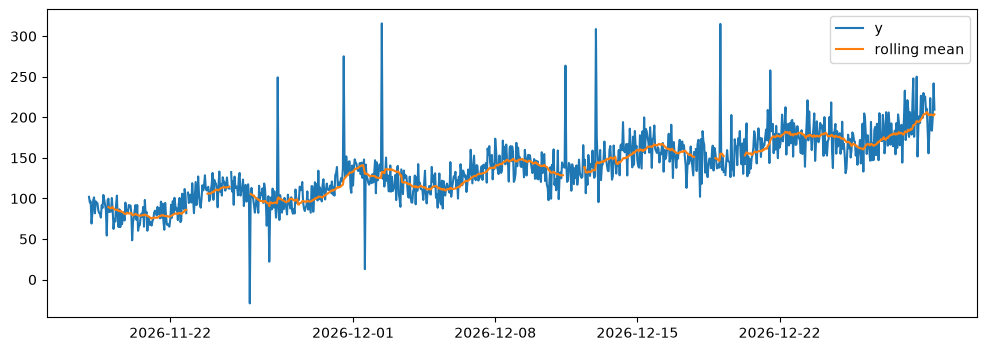

In [6]:
plt.figure(figsize=(12, 4))
plt.plot(df.index, df["value"], label="y")
plt.plot(df.index, df["rolling_mean"], label="rolling mean")
plt.legend()
plt.show()

### График скользящего стандартного отклонения

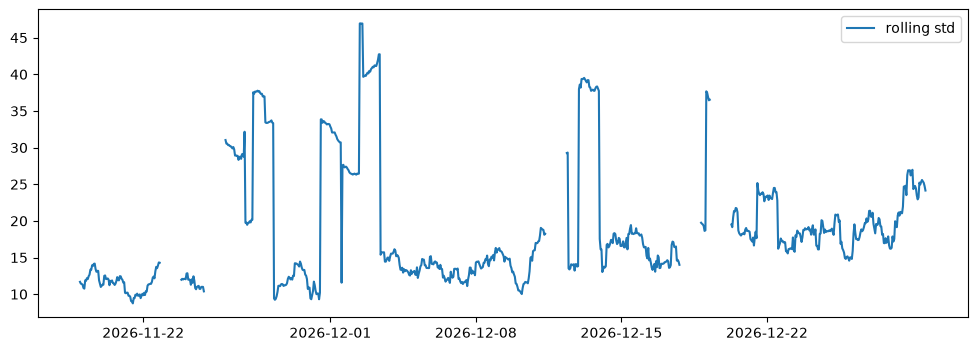

In [7]:
plt.figure(figsize=(12, 4))
plt.plot(df.index, df["rolling_std"], label="rolling std")
plt.legend()
plt.show()

### Отдельный фрагмент

In [16]:
fragment = pd.date_range("2026-11-22", "2026-12-01", freq="h")
df_frag = df.loc[fragment]

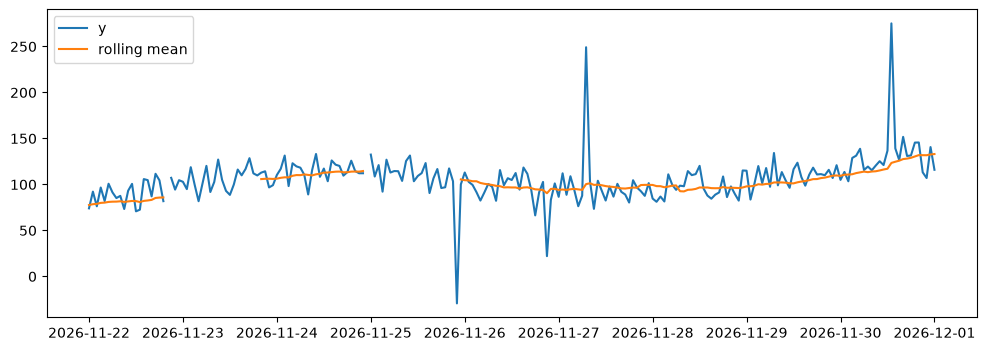

In [17]:
plt.figure(figsize=(12, 4))
plt.plot(df_frag.index, df_frag["value"], label="y")
plt.plot(df_frag.index, df_frag["rolling_mean"], label="rolling mean")
plt.legend()
plt.show()

### Сезонные подсерии

По заданию сезонность длится 7 дней, будет 7 подсерий по одной для каждого дня недели, внутри каждой подсерии - 24 часа

In [19]:
df['day_of_week'] = df.index.day_of_week  # 0 - понедельник, 1 - вторник и т.д.
df['hour'] = df.index.hour

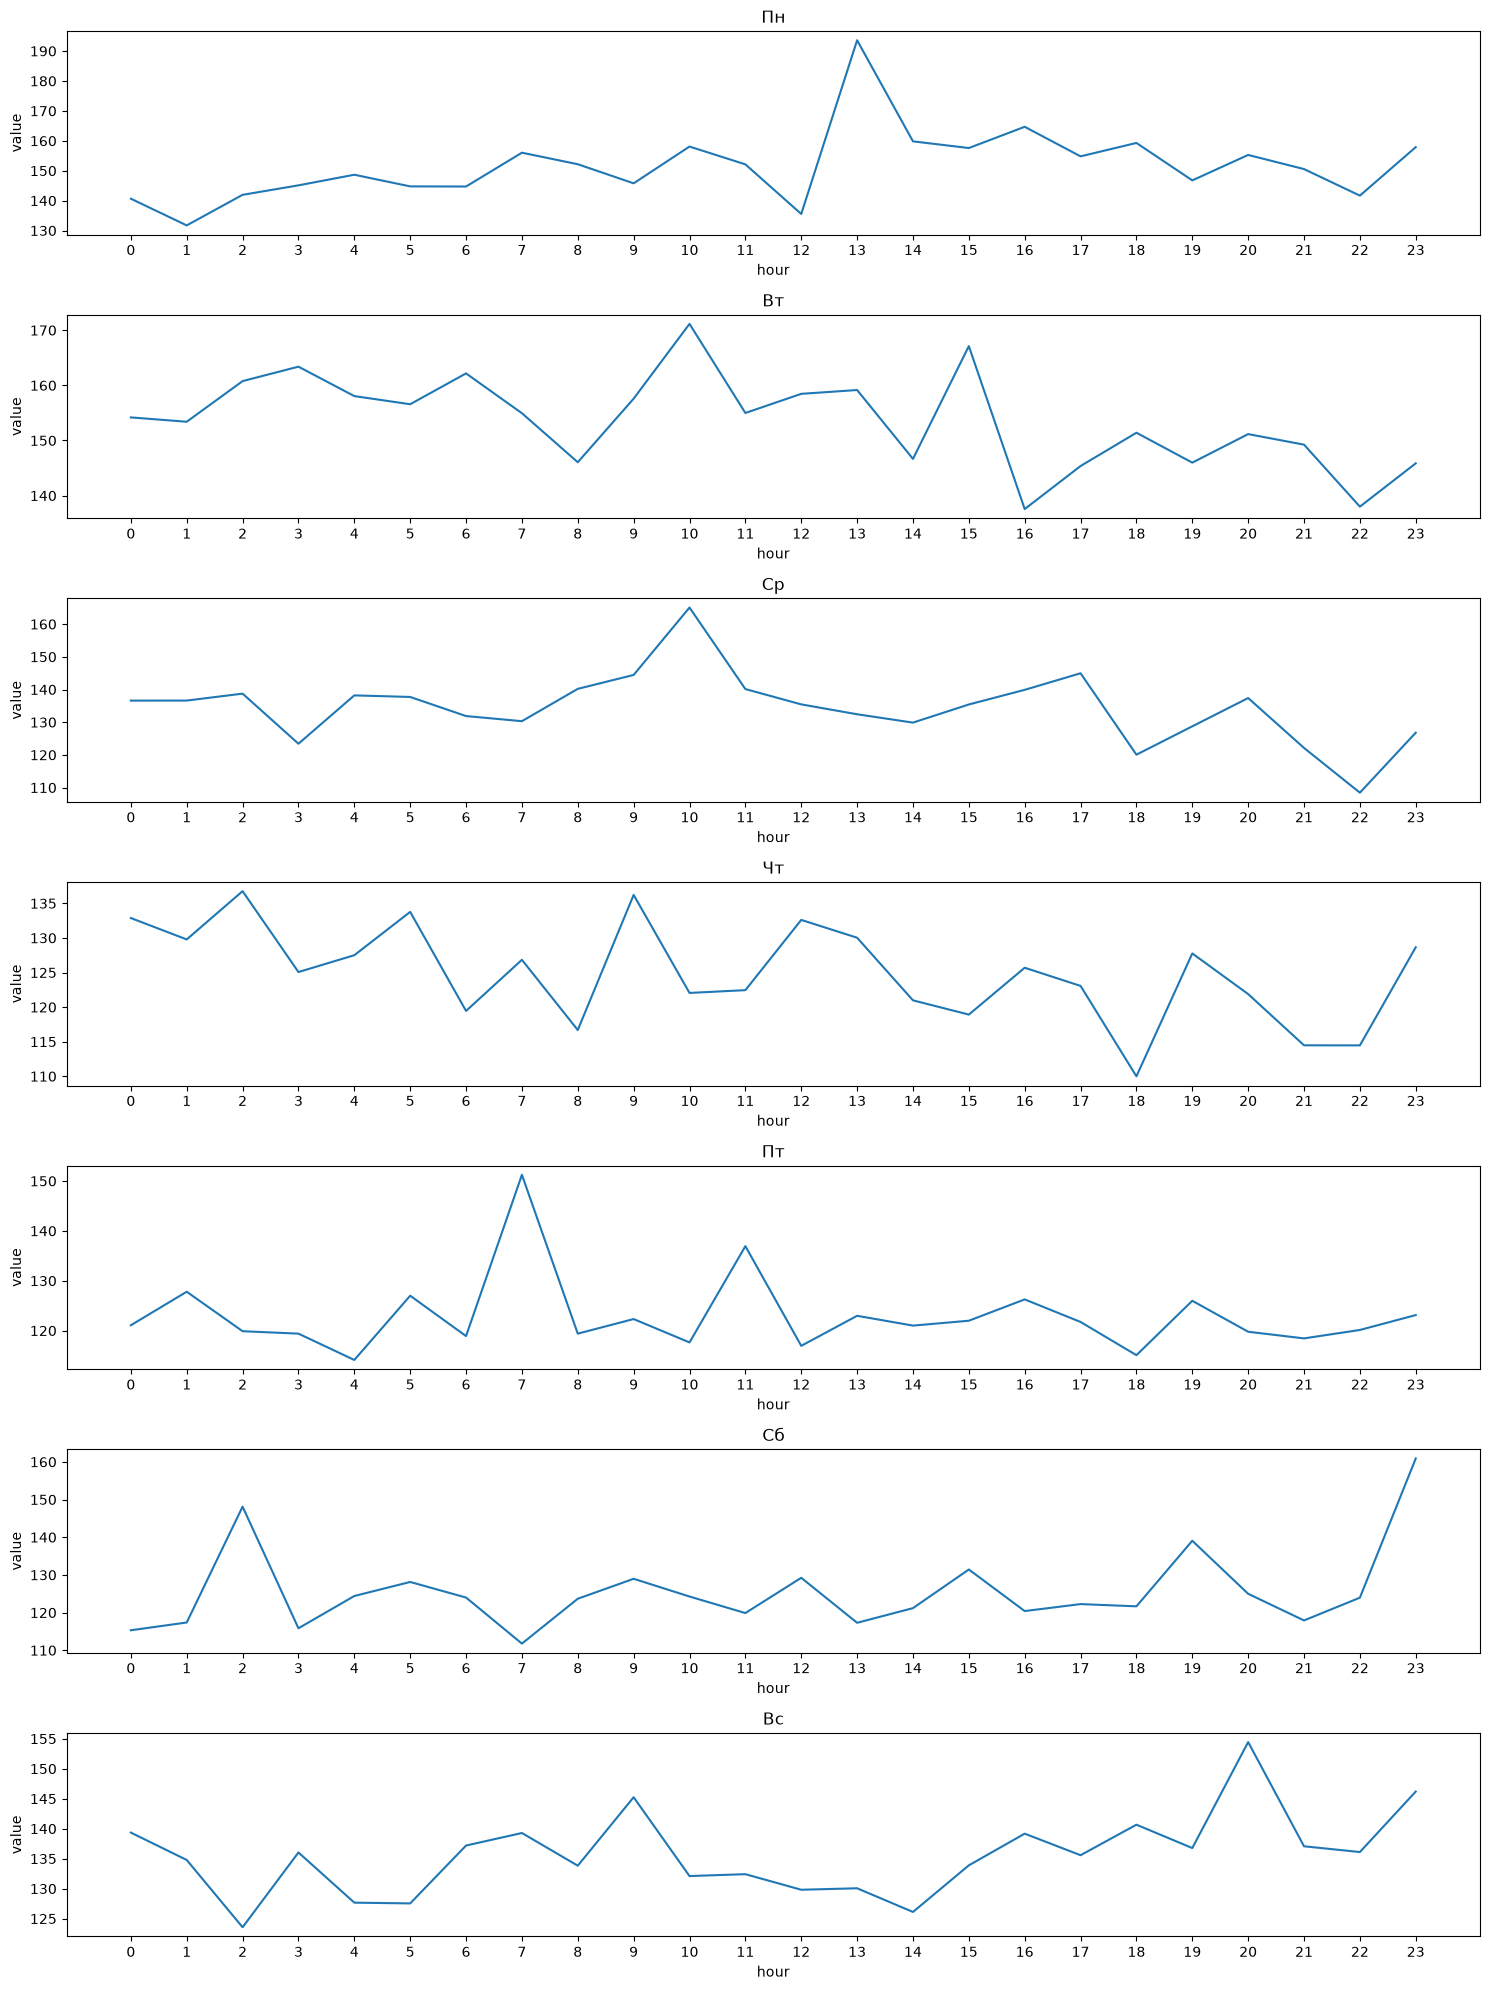

In [31]:
fig, axes = plt.subplots(7, 1, figsize=(15, 20))

for day, ax in enumerate(axes):
    subset = df[df['day_of_week'] == day]

    sns.lineplot(data=subset, x='hour', y='value', ax=ax, errorbar=None)

    ax.set_title(['Пн', 'Вт', 'Ср', 'Чт', 'Пт', 'Сб', 'Вс'][day])  # чтобы было понятнее

    ax.set_xticks(range(24))

plt.tight_layout()
plt.show()

### Тепловая карта "час x день недели"

In [32]:
heatmap_data = df.pivot_table(index='hour', columns='day_of_week', values='value', aggfunc='mean')

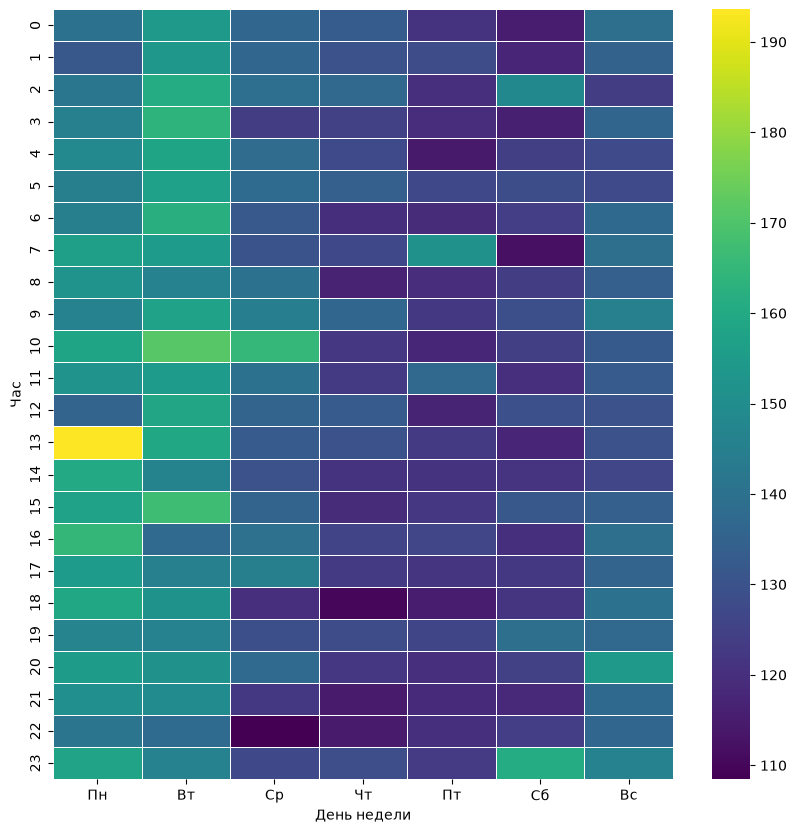

In [35]:
plt.figure(figsize=(10, 10))

sns.heatmap(heatmap_data, cmap='viridis', annot=False, linewidths=0.5)

plt.xlabel('День недели')
plt.ylabel('Час')

plt.xticks(ticks=np.arange(7) + 0.5, labels=['Пн', 'Вт', 'Ср', 'Чт', 'Пт', 'Сб', 'Вс'])

plt.show()

### Пропуски

In [40]:
df_gaps = df["value"].isna()

#### Количество

In [41]:
print(df_gaps.sum())

5


#### Где они

In [42]:
df.loc[df_gaps]

,value,rolling_mean,rolling_std,day_of_week,hour
timestamp,,,,,
2026-11-22 20:00:00,NaN,NaN,NaN,6,20
2026-11-24 23:00:00,NaN,NaN,NaN,1,23
2026-12-11 09:00:00,NaN,NaN,NaN,4,9
2026-12-17 20:00:00,NaN,NaN,NaN,3,20
2026-12-19 07:00:00,NaN,NaN,NaN,5,7


#### Самая длинная последовательность пропусков

Пояснение:

* `~` даёт отрицание
* `cumsum()` суммирует кумулятивно, если предыдущее и последующее значение одинаковы, тогда это последовательность
* `[df_gaps]` маска по последовательности с исходным DataFrame
* `value_counts()` считаем длину последовательностей
* `max()` возвращаем максимум

In [44]:
print((~df_gaps).cumsum()[df_gaps].value_counts().max())

1


Поиск выбросов через IQR

In [5]:
q1, q3 = df["value"].quantile([0.25, 0.75])
iqr = q3 - q1
df["outlier_iqr"] = (df["value"] < q1 - 1.5 * iqr) | (df["value"] > q3 + 1.5 * iqr)
df.head()

,value,rolling_mean,rolling_std,outlier_iqr
timestamp,,,,
2026-11-18 00:00:00,101.995074,NaN,NaN,False
2026-11-18 01:00:00,94.934438,NaN,NaN,False
2026-11-18 02:00:00,96.359036,NaN,NaN,False
2026-11-18 03:00:00,69.061720,NaN,NaN,False
2026-11-18 04:00:00,81.446906,NaN,NaN,False


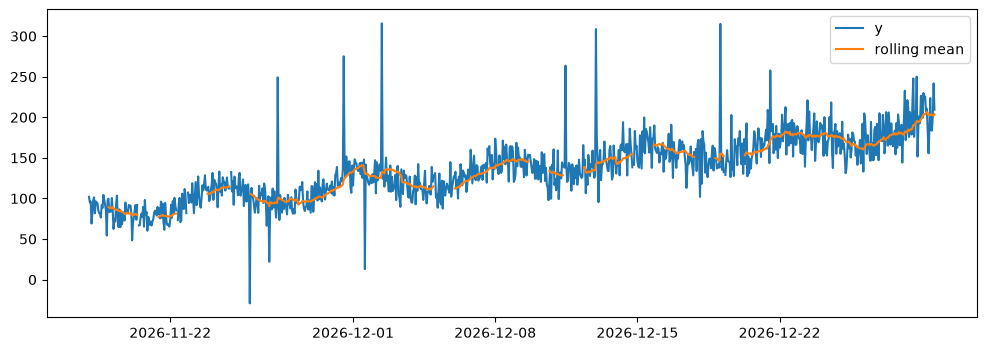

In [6]:
plt.figure(figsize=(12, 4))
plt.plot(df.index, df["value"], label="y")
plt.plot(df.index, df["rolling_mean"], label="rolling mean")
plt.legend()
plt.show()